# ODMR Detection: Stepped Averaging vs. Fast-Sweep Lock-In (IQ) Demodulation

This notebook builds up, from first principles, the difference between two ways of
finding the resonance frequency $f_0$ of an NV-center ODMR dip:

1. **Conventional stepped ODMR** — sweep the microwave frequency slowly, integrate
   long at each point, and directly see (and fit) a low-noise dip.
2. **Fast-sweep lock-in (IQ demodulation) ODMR** — sweep the frequency *fast* (so each
   individual sweep is dominated by noise), repeat the sweep many times, and extract
   $f_0$ not by averaging a whole spectrum but by demodulating against sine/cosine
   references synchronized to the sweep — analogous to a lock-in amplifier.

We use only `numpy`, `matplotlib`, and `scipy`. Every concept is simulated and plotted
before we move to the next one.

**Color convention used throughout:**
- <span style="color:blue">navy</span> = raw/measured signal
- <span style="color:orange">orange</span> = fit / smoothed / reference curve
- <span style="color:magenta">dashed magenta</span> = true (or estimated) $f_0$


## 1. Setup

We model NV fluorescence (photoluminescence, PL) vs. microwave frequency as a flat
baseline with a Lorentzian dip at resonance:

$$ \mathrm{PL}(f) = 1 - \mathrm{depth} \cdot \frac{(\mathrm{width}/2)^2}{(f-f_0)^2 + (\mathrm{width}/2)^2} $$

`depth` is the ODMR contrast (fraction of baseline lost at the dip center), and
`width` is the full width at half maximum (FWHM) of the dip, in the same units as `f`.


Based on : Welter, P., B. A. Jósteinsson, S. Josephy, et al. ‘Fast Scanning Nitrogen-Vacancy Magnetometry by Spectrum Demodulation’. Physical Review Applied 19, no. 3 (2023): 034003. https://doi.org/10.1103/PhysRevApplied.19.034003.




In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# Consistent color scheme
COLOR_SIGNAL = "navy"
COLOR_FIT = "orange"
COLOR_TRUE_F0 = "magenta"

rng = np.random.default_rng(0)  # reproducible noise


def lorentzian(f, f0, width, depth):
    '''NV fluorescence dip: flat baseline (PL=1) minus a Lorentzian resonance.'''
    return 1.0 - depth * (width / 2) ** 2 / ((f - f0) ** 2 + (width / 2) ** 2)


# Frequency axis shared by every simulation in this notebook
F_MIN, F_MAX = 2.80, 2.94  # GHz
N_FREQ = 300
freq = np.linspace(F_MIN, F_MAX, N_FREQ)

# True resonance frequency (NV zero-field splitting D ~ 2.87 GHz)
F0_TRUE = 2.87  # GHz
WIDTH = 0.004  # GHz (4 MHz FWHM)

print(f"Frequency axis: {F_MIN}-{F_MAX} GHz, {N_FREQ} points")
print(f"True resonance f0 = {F0_TRUE*1000:.1f} MHz within axis, width = {WIDTH*1000:.1f} MHz")


Frequency axis: 2.8-2.94 GHz, 300 points
True resonance f0 = 2870.0 MHz within axis, width = 4.0 MHz


## 2. Conventional ("normal") ODMR — long integration, low noise

In a standard stepped ODMR measurement, the microwave frequency is stepped point by
point, and at each point fluorescence is integrated for a relatively long time. This
gives good SNR per point: a large contrast (here 30%, not realsitic) and small noise.


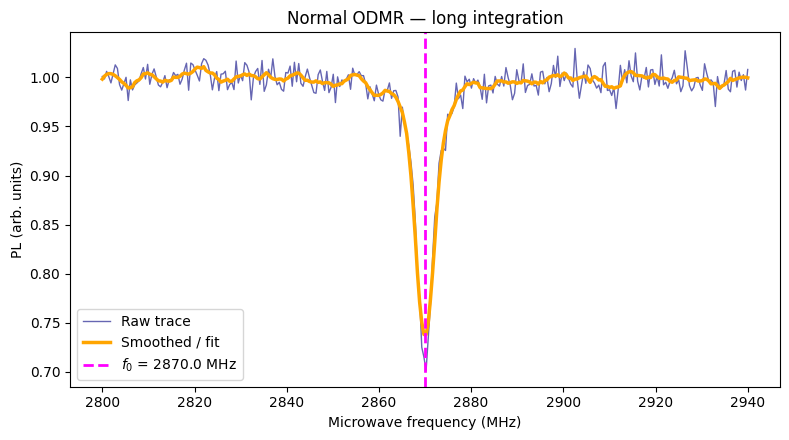

In [3]:
DEPTH_NORMAL = 0.30       # 30% contrast
NOISE_STD_NORMAL = 0.01  # small noise -> good SNR (long integration)

pl_normal = lorentzian(freq, F0_TRUE, WIDTH, DEPTH_NORMAL) + rng.normal(0, NOISE_STD_NORMAL, freq.shape)

# Light smoothing to mimic a fit / guide-the-eye curve through the low-noise data
pl_normal_smooth = savgol_filter(pl_normal, window_length=15, polyorder=3)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freq * 1000, pl_normal, color=COLOR_SIGNAL, lw=1, alpha=0.6, label="Raw trace")
ax.plot(freq * 1000, pl_normal_smooth, color=COLOR_FIT, lw=2.5, label="Smoothed / fit")
ax.axvline(F0_TRUE * 1000, color=COLOR_TRUE_F0, ls="--", lw=2, label=f"$f_0$ = {F0_TRUE*1000:.1f} MHz")
ax.set_xlabel("Microwave frequency (MHz)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Normal ODMR — long integration")
ax.legend()
fig.tight_layout()
plt.show()


## 3. Fast-sweep single-shot trace — short integration, high noise

Now imagine sweeping the same frequency range *fast*, so each point only gets a tiny
integration time. The contrast is much smaller relative to the noise (here 5% dip
depth, but 5x the noise standard deviation). A single such sweep is essentially
useless on its own for locating $f_0$.


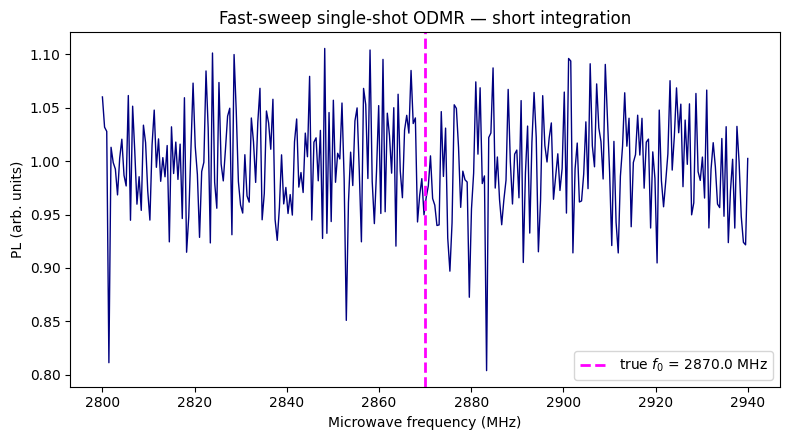

In [4]:
DEPTH_FAST = 0.05        # 5% contrast — shallow dip
NOISE_STD_FAST = 0.05    # much larger noise -> poor single-shot SNR

pl_fast_single = lorentzian(freq, F0_TRUE, WIDTH, DEPTH_FAST) + rng.normal(0, NOISE_STD_FAST, freq.shape)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freq * 1000, pl_fast_single, color=COLOR_SIGNAL, lw=1)
ax.axvline(F0_TRUE * 1000, color=COLOR_TRUE_F0, ls="--", lw=2, label=f"true $f_0$ = {F0_TRUE*1000:.1f} MHz")
ax.set_xlabel("Microwave frequency (MHz)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Fast-sweep single-shot ODMR — short integration")
ax.legend()
fig.tight_layout()
plt.show()


**This single fast sweep alone is too noisy to reliably locate $f_0$ by eye, or by
naive fitting** — the dip (5% contrast, again not realisitc compared to noise in this case) is comparable to or smaller than the
point-to-point noise. To recover a usable signal we need to combine information from
*many* repeated fast sweeps.

## 4. Many repeated noisy fast sweeps

We now simulate many independent fast sweeps of the *same* underlying resonance
(same true $f_0$), each with its own independent noise realization — exactly what a
real experiment collects when it sweeps repeatedly at kHz rates.


pl_repeats shape: (150, 300)  (repeats x frequency points)


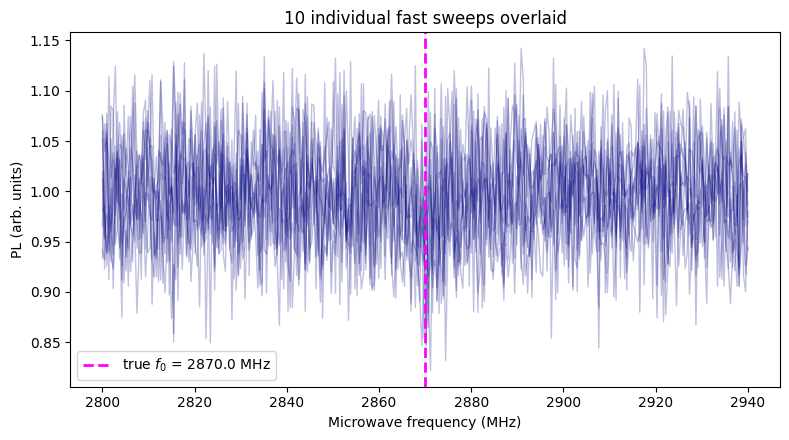

In [5]:
N_REPEATS = 150  # number of repeated fast sweeps

# 2D array: rows = repeats, columns = frequency points
pl_repeats = (
    lorentzian(freq, F0_TRUE, WIDTH, DEPTH_FAST)[None, :]
    + rng.normal(0, NOISE_STD_FAST, (N_REPEATS, N_FREQ))
)

print(f"pl_repeats shape: {pl_repeats.shape}  (repeats x frequency points)")

fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(10):
    ax.plot(freq * 1000, pl_repeats[i], color=COLOR_SIGNAL, lw=1, alpha=0.25)
ax.axvline(F0_TRUE * 1000, color=COLOR_TRUE_F0, ls="--", lw=2, label=f"true $f_0$ = {F0_TRUE*1000:.1f} MHz")
ax.set_xlabel("Microwave frequency (MHz)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("10 individual fast sweeps overlaid")
ax.legend()
fig.tight_layout()
plt.show()


## 5. Naive averaging approach

The simplest way to combine the repeated sweeps is a plain point-by-point average across all repeats. With enough repeats, the dip does emerge from the noise.


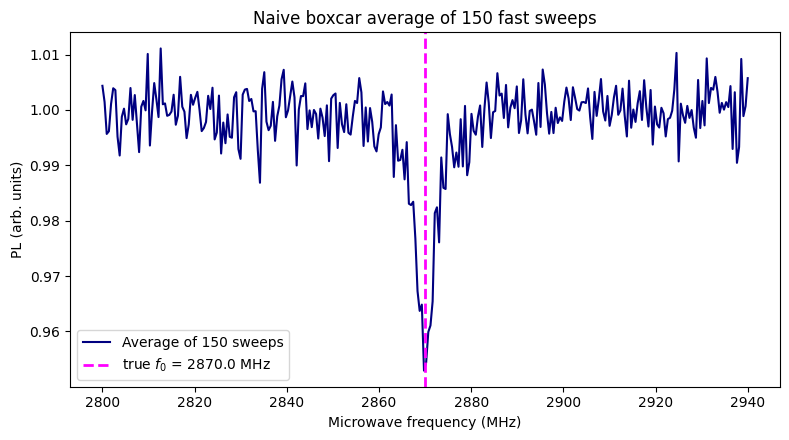

In [6]:
pl_avg_naive = pl_repeats.mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(freq * 1000, pl_avg_naive, color=COLOR_SIGNAL, lw=1.5, label=f"Average of {N_REPEATS} sweeps")
ax.axvline(F0_TRUE * 1000, color=COLOR_TRUE_F0, ls="--", lw=2, label=f"true $f_0$ = {F0_TRUE*1000:.1f} MHz")
ax.set_xlabel("Microwave frequency (MHz)")
ax.set_ylabel("PL (arb. units)")
ax.set_title(f"Naive boxcar average of {N_REPEATS} fast sweeps")
ax.legend()
fig.tight_layout()
plt.show()


The dip is now visible — but notice what this required: **storing and averaging
the entire trace (all `N_FREQ` frequency points) for every single repeat.** For a fast
kHz-rate sweep this is a lot of data bandwidth just to get one number ($f_0$) out.


## 6. Lock-in / IQ demodulation approach

Instead of storing full spectra, a lock-in scheme treats one sweep as one cycle of a
periodic reference. We map the frequency axis to a **phase** $\theta \in [0, 2\pi)$
that advances linearly across the sweep (since, in the real system, frequency maps
linearly to time within a sweep), and build sine/cosine reference waveforms
synchronized to it.


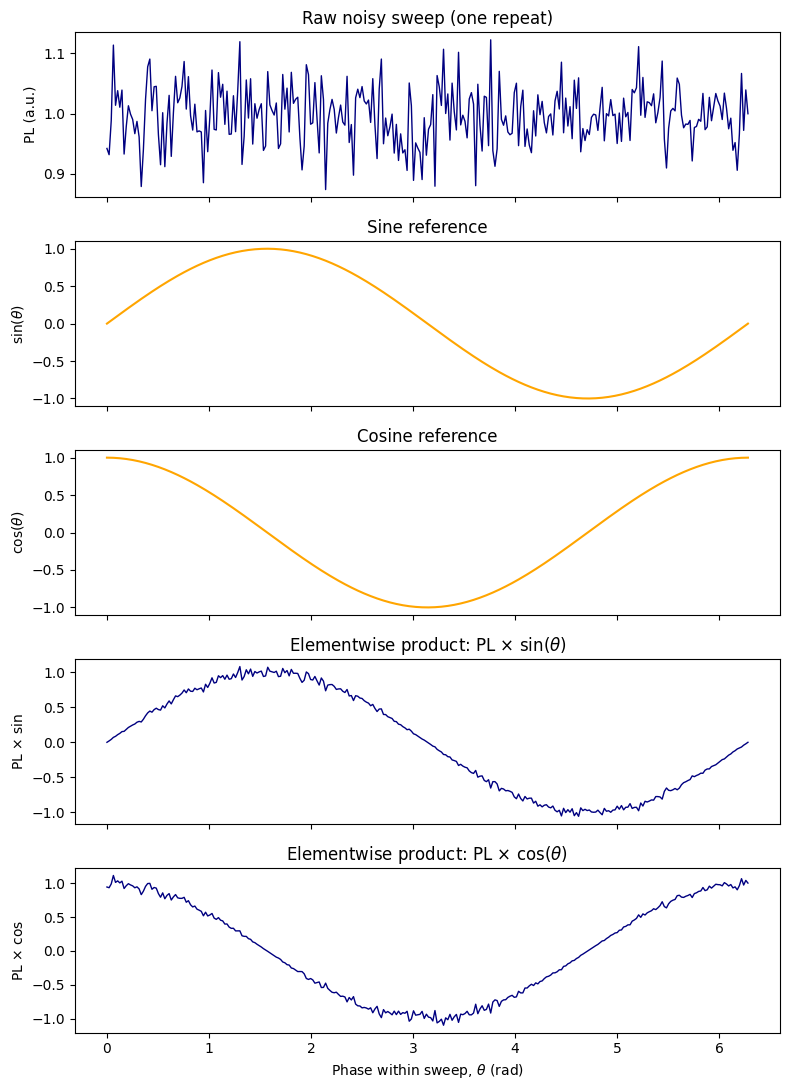

In [7]:
theta = 2 * np.pi * (freq - F_MIN) / (F_MAX - F_MIN)  # phase within one sweep cycle
sin_ref = np.sin(theta)
cos_ref = np.cos(theta)

# Take one example noisy sweep and show what "multiplying by the reference" produces
example_sweep = pl_repeats[0]
product_sin = example_sweep * sin_ref
product_cos = example_sweep * cos_ref

fig, axes = plt.subplots(5, 1, figsize=(8, 11), sharex=True)

axes[0].plot(theta, example_sweep, color=COLOR_SIGNAL, lw=1)
axes[0].set_ylabel("PL (a.u.)")
axes[0].set_title("Raw noisy sweep (one repeat)")

axes[1].plot(theta, sin_ref, color=COLOR_FIT, lw=1.5)
axes[1].set_ylabel("sin($\\theta$)")
axes[1].set_title("Sine reference")

axes[2].plot(theta, cos_ref, color=COLOR_FIT, lw=1.5)
axes[2].set_ylabel("cos($\\theta$)")
axes[2].set_title("Cosine reference")

axes[3].plot(theta, product_sin, color=COLOR_SIGNAL, lw=1)
axes[3].set_ylabel("PL $\\times$ sin")
axes[3].set_title("Elementwise product: PL $\\times$ sin($\\theta$)")

axes[4].plot(theta, product_cos, color=COLOR_SIGNAL, lw=1)
axes[4].set_ylabel("PL $\\times$ cos")
axes[4].set_title("Elementwise product: PL $\\times$ cos($\\theta$)")
axes[4].set_xlabel("Phase within sweep, $\\theta$ (rad)")

fig.tight_layout()
plt.show()


The product traces wiggle rapidly and mostly average toward zero — **except**
near the dip, where the missing fluorescence briefly breaks the symmetry between the
positive and negative half-cycles of the reference. That small systematic imbalance,
accumulated over many points and many repeats, is exactly what lock-in detection
extracts.


### Intermezzo What do $I$ and $Q$ actually measure?

Before collapsing everything into two numbers, it helps to look directly at how the
raw PL trace lines up with each reference wave. $I$ is essentially asking: across the
sweep, does PL tend to be high when $\cos\theta$ is high and low when $\cos\theta$ is
low (in step / positively correlated), does it tend to do the opposite (out of step /
negatively correlated), or is there no consistent relationship at all (uncorrelated —
what pure noise looks like)? The overlay below plots the raw noisy PL trace and
$\cos\theta$ on separate y-axes so their ups and downs can be compared directly at
each phase.

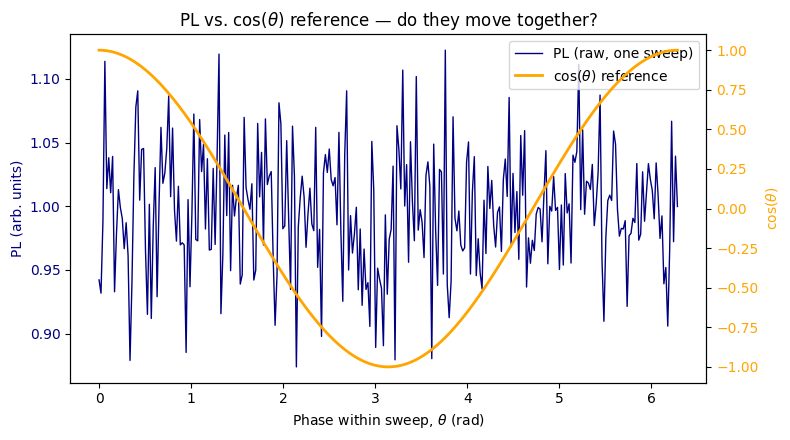

In [8]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(theta, example_sweep, color=COLOR_SIGNAL, lw=1, label="PL (raw, one sweep)")
ax1.set_xlabel("Phase within sweep, $\\theta$ (rad)")
ax1.set_ylabel("PL (arb. units)", color=COLOR_SIGNAL)
ax1.tick_params(axis="y", labelcolor=COLOR_SIGNAL)

ax2 = ax1.twinx()
ax2.plot(theta, cos_ref, color=COLOR_FIT, lw=2, label="cos($\\theta$) reference")
ax2.set_ylabel("cos($\\theta$)", color=COLOR_FIT)
ax2.tick_params(axis="y", labelcolor=COLOR_FIT)

ax1.set_title("PL vs. cos($\\theta$) reference — do they move together?")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

fig.tight_layout()
plt.show()

The same comparison, now for the sine reference: $Q$ captures how strongly PL
correlates with $\sin\theta$ instead of $\cos\theta$. Since $\sin\theta$ and
$\cos\theta$ are 90$^\circ$ out of phase with each other, having *both* correlations
lets us pin down not just *whether* PL dips somewhere in the sweep, but *where* —
exactly the information needed to recover $f_0$.

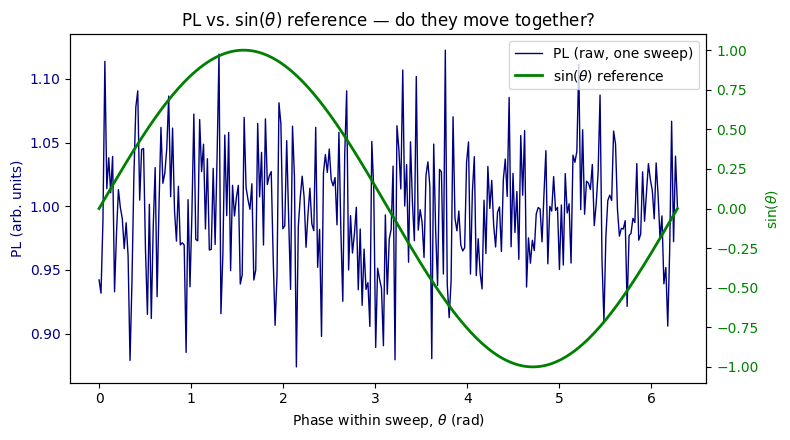

In [9]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(theta, example_sweep, color=COLOR_SIGNAL, lw=1, label="PL (raw, one sweep)")
ax1.set_xlabel("Phase within sweep, $\\theta$ (rad)")
ax1.set_ylabel("PL (arb. units)", color=COLOR_SIGNAL)
ax1.tick_params(axis="y", labelcolor=COLOR_SIGNAL)

ax2 = ax1.twinx()
ax2.plot(theta, sin_ref, color="green", lw=2, label="sin($\\theta$) reference")
ax2.set_ylabel("sin($\\theta$)", color="green")
ax2.tick_params(axis="y", labelcolor="green")

ax1.set_title("PL vs. sin($\\theta$) reference — do they move together?")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

fig.tight_layout()
plt.show()

### Intermezzo Making the correlation concrete: sign agreement

To turn "do they move together" into something visual, check at every phase point
whether the (baseline-subtracted) PL and the reference wave have the **same sign** —
are they both above, or both below, their respective zero lines at the same time?
Where they agree (shaded green), that point contributes *positively* to the product
$\mathrm{PL}\times\cos\theta$ and pushes $I$ upward; where they disagree (shaded pink),
it contributes *negatively*. Away from the resonance, PL is just noise, so agreement
is roughly a coin flip and the shading looks like a fairly even, random mix. Near the
dip, the missing fluorescence tilts that coin flip slightly — the shading there leans
more green than the flat regions do — which is exactly the small residual imbalance
that survives averaging into $I$. For a single noisy sweep this tilt is subtle by eye
(it only really shows up once you average over many sweeps, as the next cells do); the
important point is that it is systematic, not random, so it doesn't cancel out the
way the noise elsewhere does.

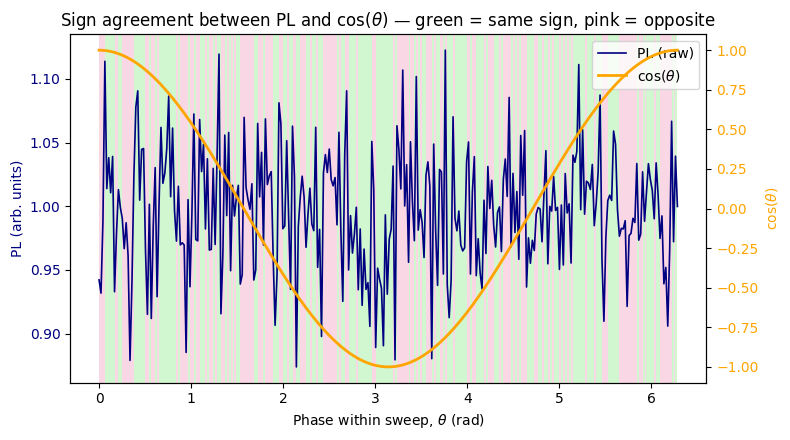

In [10]:
pl_centered = example_sweep - np.mean(example_sweep)  # remove DC baseline
agreement = np.sign(pl_centered) == np.sign(cos_ref)   # True where signs match

fig, ax1 = plt.subplots(figsize=(8, 4.5))

# Shade contiguous same-sign segments in the background
change_idx = np.where(np.diff(agreement.astype(int)) != 0)[0] + 1
bounds = np.concatenate(([0], change_idx, [len(theta) - 1]))
for start, end in zip(bounds[:-1], bounds[1:]):
    shade_color = "#bdf5bd" if agreement[start] else "#f7c6da"
    ax1.axvspan(theta[start], theta[end], color=shade_color, alpha=0.7, lw=0, zorder=0)

ax1.plot(theta, example_sweep, color=COLOR_SIGNAL, lw=1.2, label="PL (raw)", zorder=2)
ax1.set_xlabel("Phase within sweep, $\\theta$ (rad)")
ax1.set_ylabel("PL (arb. units)", color=COLOR_SIGNAL)
ax1.tick_params(axis="y", labelcolor=COLOR_SIGNAL)

ax2 = ax1.twinx()
ax2.plot(theta, cos_ref, color=COLOR_FIT, lw=2, label="cos($\\theta$)", zorder=2)
ax2.set_ylabel("cos($\\theta$)", color=COLOR_FIT)
ax2.tick_params(axis="y", labelcolor=COLOR_FIT)

ax1.set_title("Sign agreement between PL and cos($\\theta$) — green = same sign, pink = opposite")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

fig.tight_layout()
plt.show()

### Intermezzo Cummulative means


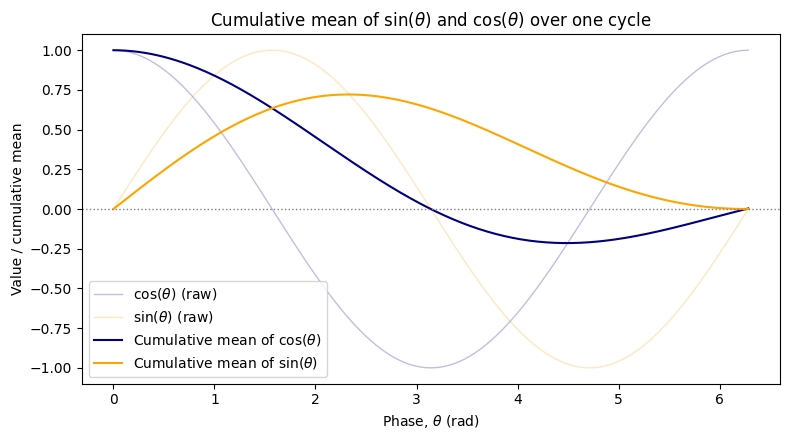

In [17]:
# Cumulative mean of a sine and cosine wave over one full cycle
n_pts = np.arange(1, len(theta) + 1)
cum_mean_cos = np.cumsum(cos_ref) / n_pts
cum_mean_sin = np.cumsum(sin_ref) / n_pts

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(theta, cos_ref, color=COLOR_SIGNAL, lw=1, alpha=0.25, label="cos($\\theta$) (raw)")
ax.plot(theta, sin_ref, color=COLOR_FIT, lw=1, alpha=0.25, label="sin($\\theta$) (raw)")
ax.plot(theta, cum_mean_cos, color=COLOR_SIGNAL, lw=1.5, label="Cumulative mean of cos($\\theta$)")
ax.plot(theta, cum_mean_sin, color=COLOR_FIT, lw=1.5, label="Cumulative mean of sin($\\theta$)")
ax.axhline(0, color="gray", ls=":", lw=1)
ax.set_xlabel("Phase, $\\theta$ (rad)")
ax.set_ylabel("Value / cumulative mean")
ax.set_title("Cumulative mean of sin($\\theta$) and cos($\\theta$) over one cycle")
ax.legend()
fig.tight_layout()
plt.show()

### Watching $I$ and $Q$ emerge: the running average

Going back to the PL x $\sin\theta$, rather than only reporting the final $I$ value, we can watch it build up point by
point: compute the running (cumulative) average of the product
$\mathrm{PL}\times\cos\theta$ as more and more phase points within one sweep are
folded in. Because $\cos\theta$ itself is a smooth, deterministic curve (not noise),
the running average below traces a smooth arc that mostly reflects *how much of the
positive half-cycle vs. the negative half-cycle of the reference has been integrated
so far* — it is not yet the noise-driven "settling" a lock-in relies on. What
matters is the **endpoint**: because a full cycle of $\cos\theta$ integrates to zero
on its own, the value left over once the whole sweep is included is only the small
residual caused by the dip — that residual *is* $I$ (and likewise for $\sin\theta$
and $Q$). One sweep only offers this one endpoint, so it is still a noisy, unreliable
estimate on its own. Genuine noise-averaging convergence only appears once we combine
many *independent* sweeps, which is exactly the next plot.

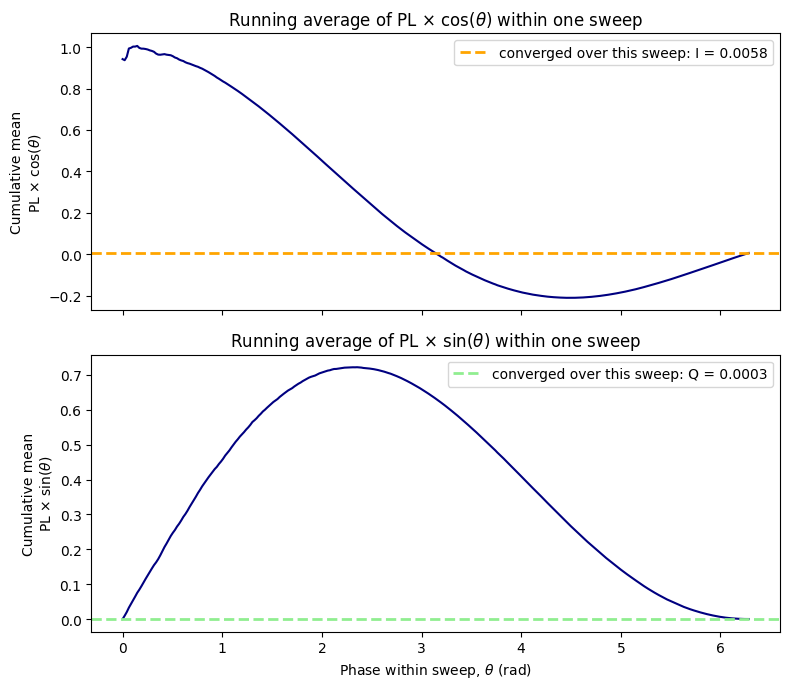

In [12]:
n_pts = np.arange(1, len(theta) + 1)
cum_I_single = np.cumsum(product_cos) / n_pts
cum_Q_single = np.cumsum(product_sin) / n_pts

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)

axes[0].plot(theta, cum_I_single, color=COLOR_SIGNAL, lw=1.5)
axes[0].axhline(cum_I_single[-1], color=COLOR_FIT, ls="--", lw=2,
                label=f"converged over this sweep: I = {cum_I_single[-1]:.4f}")
axes[0].set_ylabel("Cumulative mean\nPL $\\times$ cos($\\theta$)")
axes[0].set_title("Running average of PL $\\times$ cos($\\theta$) within one sweep")
axes[0].legend()

axes[1].plot(theta, cum_Q_single, color=COLOR_SIGNAL, lw=1.5)
axes[1].axhline(cum_Q_single[-1], color="lightgreen", ls="--", lw=2,
                label=f"converged over this sweep: Q = {cum_Q_single[-1]:.4f}")
axes[1].set_ylabel("Cumulative mean\nPL $\\times$ sin($\\theta$)")
axes[1].set_xlabel("Phase within sweep, $\\theta$ (rad)")
axes[1].set_title("Running average of PL $\\times$ sin($\\theta$) within one sweep")
axes[1].legend()

fig.tight_layout()
plt.show()

### From one sweep to many: genuine convergence across repeats

Each repeat gives one independent, noisy endpoint value like the one above. Now
instead of averaging *within* a sweep, we average *across* sweeps: each repeat first
contributes its own sweep-integrated product value (a single noisy number, dominated
by that repeat's particular noise draw), and we take the running average of *those*
as more repeats are folded in. This is where the classic noise-cancellation "wiggle
that settles down" actually appears — the single-sweep estimate (leftmost point) can
sit far from the truth, but as more independent repeats accumulate, the curve
converges onto the same converged $I$ computed earlier from the full `N_REPEATS`
dataset. This is literally what a lock-in amplifier's low-pass filter does
continuously in real time, and it is also the reason a fast kHz-rate sweep only
delivers a much lower *effective* output rate once enough repeats have been folded in
to trust the estimate.

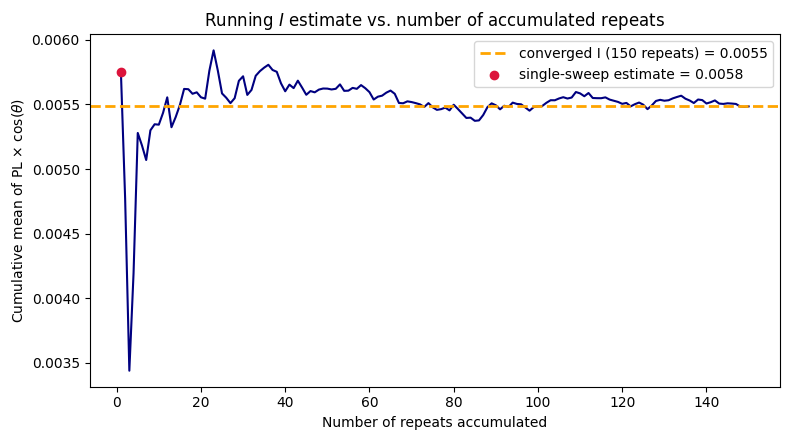

I from a single sweep:            0.0058
I converged over 150 repeats:      0.0055


In [13]:
# Each repeat's own sweep-averaged product (one number per repeat)
per_sweep_mean_cos = np.mean(pl_repeats * cos_ref[None, :], axis=1)  # shape (N_REPEATS,)

repeat_idx = np.arange(1, N_REPEATS + 1)
cum_I_repeats = np.cumsum(per_sweep_mean_cos) / repeat_idx

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(repeat_idx, cum_I_repeats, color=COLOR_SIGNAL, lw=1.5)
ax.axhline(cum_I_repeats[-1], color=COLOR_FIT, ls="--", lw=2,
           label=f"converged I ({N_REPEATS} repeats) = {cum_I_repeats[-1]:.4f}")
ax.scatter([1], [cum_I_repeats[0]], color="crimson", zorder=5,
           label=f"single-sweep estimate = {cum_I_repeats[0]:.4f}")
ax.set_xlabel("Number of repeats accumulated")
ax.set_ylabel("Cumulative mean of PL $\\times$ cos($\\theta$)")
ax.set_title("Running $I$ estimate vs. number of accumulated repeats")
ax.legend()
fig.tight_layout()
plt.show()

print(f"I from a single sweep:            {cum_I_repeats[0]:.4f}")
print(f"I converged over {N_REPEATS} repeats:      {cum_I_repeats[-1]:.4f}")

In [ ]:
# Accumulate the products over the FULL dataset: every frequency point, every repeat
I = np.mean(pl_repeats * cos_ref[None, :])
Q = np.mean(pl_repeats * sin_ref[None, :])

print(f"I = {I:.6f}")
print(f"Q = {Q:.6f}")


I = 0.005485
Q = -0.000207


These two numbers, $I$ and $Q$, are the accumulated in-phase and quadrature
components of the fluorescence signal, integrated over both the sweep and all
repeats. **They replace the need to store or fit an entire averaged spectrum** — the
whole `N_REPEATS` $\times$ `N_FREQ` dataset has been condensed on-the-fly into two
scalars.


## 7. Recovering $f_0$ from $I$ and $Q$

The dip's position within the sweep sets the *phase* of the demodulated signal: a dip
exactly opposite the reference phase (deficit strongest when $\cos\theta$ is most
negative) shows up as a phase offset of $I,Q$ relative to $\theta_0$. We recover that
phase with `arctan2`, correct for the fixed $\pi$ offset introduced by the dip being a
*deficit* (negative-going) rather than a positive bump, and map back to frequency
using the same linear $\theta \leftrightarrow f$ relationship used to build the
references.


In [ ]:
phase = np.arctan2(Q, I)

# The dip is a *negative*-going feature, so the demodulated phase is offset by pi
# relative to the dip's actual phase location theta0 within the sweep.
theta0_estimate = (phase - np.pi) % (2 * np.pi)

# Map phase back to frequency using the same linear theta <-> f relationship
f0_estimate = F_MIN + (F_MAX - F_MIN) * theta0_estimate / (2 * np.pi)

error_MHz = (f0_estimate - F0_TRUE) * 1000

print(f"True f0:      {F0_TRUE*1000:.2f} MHz")
print(f"Estimated f0: {f0_estimate*1000:.2f} MHz  (from IQ demodulation, {N_REPEATS} repeats)")
print(f"Error:        {error_MHz:+.2f} MHz")


True f0:      2870.00 MHz
Estimated f0: 2869.16 MHz  (from IQ demodulation, 150 repeats)
Error:        -0.84 MHz


## 8. Summary comparison

Both routes — easy averaging of the full spectrum, and IQ demodulation down to
two numbers — converge on the same resonance frequency.


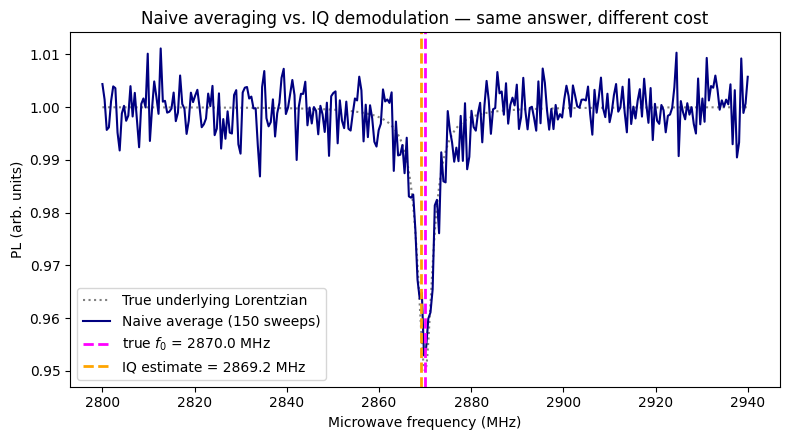

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))

f_fine = np.linspace(F_MIN, F_MAX, 1000)
true_curve = lorentzian(f_fine, F0_TRUE, WIDTH, DEPTH_FAST)
ax.plot(f_fine * 1000, true_curve, color="gray", lw=1.5, ls=":", label="True underlying Lorentzian")

ax.plot(freq * 1000, pl_avg_naive, color=COLOR_SIGNAL, lw=1.5, label=f"Naive average ({N_REPEATS} sweeps)")

ax.axvline(F0_TRUE * 1000, color=COLOR_TRUE_F0, ls="--", lw=2, label=f"true $f_0$ = {F0_TRUE*1000:.1f} MHz")
ax.axvline(f0_estimate * 1000, color=COLOR_FIT, ls="--", lw=2, label=f"IQ estimate = {f0_estimate*1000:.1f} MHz")

ax.set_xlabel("Microwave frequency (MHz)")
ax.set_ylabel("PL (arb. units)")
ax.set_title("Naive averaging vs. IQ demodulation — same answer, different cost")
ax.legend()
fig.tight_layout()
plt.show()


## 9. Convergence of the IQ estimate with more averaging

The fast-sweep/lock-in scheme trades a high raw sweep rate (kHz) for a much lower
*effective* output rate (e.g. ~100 Hz) once enough sweeps have been accumulated to
beat down the noise. Here we sweep the number of averaged repeats and track how the
IQ-demodulation frequency error shrinks — each point below averages many independent
trials at that repeat count to show the underlying trend (roughly $1/\sqrt{N}$).


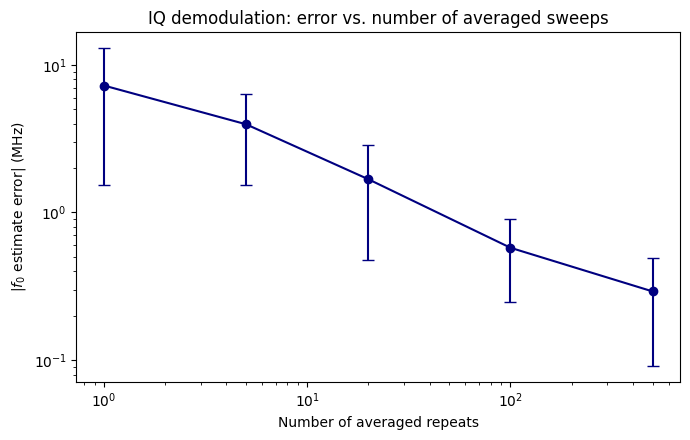

N =    1 repeats -> mean |error| = 7.23 MHz
N =    5 repeats -> mean |error| = 3.96 MHz
N =   20 repeats -> mean |error| = 1.68 MHz
N =  100 repeats -> mean |error| = 0.58 MHz
N =  500 repeats -> mean |error| = 0.29 MHz


In [ ]:
def estimate_f0_from_iq(n_repeats, rng_local):
    '''Simulate n_repeats fast sweeps and return the IQ-demodulated f0 estimate.'''
    pl = (
        lorentzian(freq, F0_TRUE, WIDTH, DEPTH_FAST)[None, :]
        + rng_local.normal(0, NOISE_STD_FAST, (n_repeats, N_FREQ))
    )
    I_ = np.mean(pl * cos_ref[None, :])
    Q_ = np.mean(pl * sin_ref[None, :])
    theta0_ = (np.arctan2(Q_, I_) - np.pi) % (2 * np.pi)
    return F_MIN + (F_MAX - F_MIN) * theta0_ / (2 * np.pi)


repeat_counts = [1, 5, 20, 100, 500]
n_trials = 40  # independent trials per repeat count, to average out estimate scatter

mean_err_MHz = []
std_err_MHz = []
rng_bonus = np.random.default_rng(123)

for n in repeat_counts:
    errs = [abs(estimate_f0_from_iq(n, rng_bonus) - F0_TRUE) * 1000 for _ in range(n_trials)]
    mean_err_MHz.append(np.mean(errs))
    std_err_MHz.append(np.std(errs))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(repeat_counts, mean_err_MHz, yerr=std_err_MHz, color=COLOR_SIGNAL,
            marker="o", capsize=4, lw=1.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of averaged repeats")
ax.set_ylabel("$|f_0$ estimate error| (MHz)")
ax.set_title("IQ demodulation: error vs. number of averaged sweeps")
fig.tight_layout()
plt.show()

for n, e in zip(repeat_counts, mean_err_MHz):
    print(f"N = {n:4d} repeats -> mean |error| = {e:.2f} MHz")
